# Simple and multiple regression: energy, market and oil

This analysis compares a market-only regression with a specification including
Brent price changes. Coefficients, standard errors and confidence intervals describe
the estimated relationships; residual variation and model fit support the comparison.

The analysis uses monthly observations for **2011–2025**: US energy-sector portfolio
returns, broad US equity-market returns and Brent spot prices.

Data Sources:

- Value-weighted market and energy-sector portfolios, and monthly risk-free returns:
  [Ken French industry portfolios](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_12_ind_port.html)
  and [factor data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html);
- EIA observations: FRED [Brent](https://fred.stlouisfed.org/series/DCOILBRENTEU).

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data

In [3]:
# Load monthly observations and use month-end labels as the index.
# December 2010 supplies the base price for the first Brent change.
data = pd.read_csv(
    DATA_DIR / "monthly_energy_market_data.csv",
    index_col="date",
    parse_dates=["date", "Brent_observation_date"]
).sort_index()
data = data.loc["2010-12-01":"2025-12-31"]
display(data.head())

,Energy,Market_excess,RF,Brent_spot,Brent_observation_date
date,,,,,
2010-12-31,0.0941,0.0682,0.0001,93.23,2010-12-31
2011-01-31,0.0693,0.0198,0.0001,98.97,2011-01-31
2011-02-28,0.0763,0.0348,0.0001,112.27,2011-02-28
2011-03-31,0.0211,0.0045,0.0001,116.94,2011-03-31
2011-04-30,0.0158,0.0290,0.0000,126.59,2011-04-28


In [4]:
# Energy is a value-weighted sector portfolio total return, including dividends.
# Subtract the matched monthly RF to obtain its excess return.
# Market_excess is already Mkt-RF: do not subtract RF again.
# The CRSP market covers eligible US stocks on NYSE, AMEX and NASDAQ, not the S&P 500.
# RF is a monthly return, rather than an annualised yield.

# Brent_spot is the last available price in each month, not an investment return.
# Calculate its simple percentage change before excluding the December 2010 base.
# No forward filling is used; Brent_observation_date records the price's actual date.

# Convert decimal returns to percent: one unit means one percentage point.
returns = pd.DataFrame({
    "Energy": 100 * (data["Energy"] - data["RF"]),
    "Market": 100 * data["Market_excess"],
    "Brent": 100 * data["Brent_spot"].pct_change(fill_method=None),
}).loc["2011-01-01":"2025-12-31"]

# Both models use exactly the same 180 months; missing values require inspection.
if returns.isna().any().any():
    raise ValueError("Missing observations: check the data before comparing the models.")
print(f"Estimation sample: {returns.index[0]:%Y-%m} to {returns.index[-1]:%Y-%m}; {len(returns)} months")
display(returns.head().round(3))

Estimation sample: 2011-01 to 2025-12; 180 months


,Energy,Market,Brent
date,,,
2011-01-31,6.92,1.98,6.157
2011-02-28,7.62,3.48,13.438
2011-03-31,2.10,0.45,4.160
2011-04-30,1.58,2.90,8.252
2011-05-31,-4.51,-1.27,-7.433


## Simple regression: the market model

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+u_t.$$

**Alpha** is fitted energy excess return when Market is zero. **Beta** is its change,
in percentage points, for a one-percentage-point increase in Market. For example,
a beta of 1.2 associates a 1 pp market increase with a 1.2 pp increase in fitted
energy return. This does not mean that every observed energy return follows that rule:
the residual is the difference between the observed and fitted return.

This CAPM-style regression uses a sector portfolio; CAPM reasoning also applies
to individual stocks. With an appropriate market portfolio and the CAPM assumptions,
the pricing restriction implies zero alpha. Estimating this regression alone does
not validate the CAPM.

Both models use OLS coefficients and **Newey–West HAC standard errors with three
monthly lags**. HAC allows heteroskedasticity and short-run serial dependence;
it changes estimated uncertainty, not coefficients or fitted values.

In [5]:
y = returns["Energy"]
# Newey–West HAC: Bartlett weights, three monthly lags and a sample-size correction.
# The t reference used for robust inference is an approximation, not an exact test.
HAC_OPTIONS = {"maxlags": 3, "kernel": "bartlett", "use_correction": True}

X_simple = sm.add_constant(returns[["Market"]])
simple = sm.OLS(y, X_simple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     35.97
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           1.09e-08
Time:                        18:49:52   Log-Likelihood:                -577.72
No. Observations:                 180   AIC:                             1159.
Df Residuals:                     178   BIC:                             1166.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.6295      0.576     -1.093      0.2

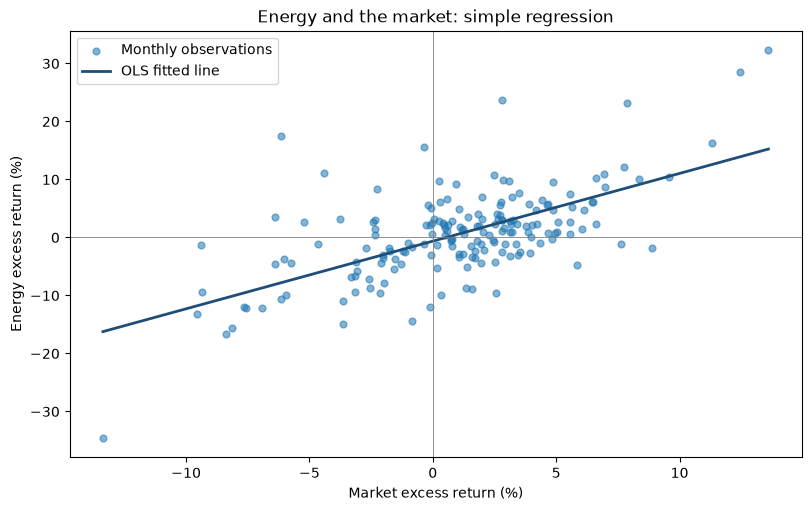

In [6]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.scatter(returns["Market"], y, s=24, alpha=0.55, label="Monthly observations")
market_grid = np.linspace(returns["Market"].min(), returns["Market"].max(), 100)
ax.plot(market_grid, simple.params["const"] + simple.params["Market"] * market_grid,
        color="#1F4E79", lw=2, label="OLS fitted line")
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set(xlabel="Market excess return (%)", ylabel="Energy excess return (%)",
       title="Energy and the market: simple regression")
ax.legend()
plt.show()

The **standard error** measures sampling uncertainty about a coefficient, not return
volatility or residual dispersion. A smaller standard error means a more precise
estimate. The reported statistic is $t=\hat\theta/SE(\hat\theta)$, testing
$H_0:\theta=0$ against $H_1:\theta\ne0$; for beta, this is not a test of beta = 1.

Under the null and test assumptions, the **p-value** is the probability of a statistic
at least as extreme as observed. It is not the probability that the null is true,
and it does not measure the size of the relationship. At 5%, reject when $p<0.05$;
non-rejection does not establish that the coefficient is zero. A Type I error is
rejecting a true null. A displayed `0.000` is rounding.

A **95% confidence-interval procedure** covers the true coefficient in 95% of repeated
samples under its assumptions. The interval excludes zero exactly when the matching
two-sided 5% test rejects. HAC inference is approximate; economic importance and
statistical significance remain separate considerations.

## Multiple regression: adding Brent

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+\beta_O\Delta p^{Brent}_t+u_t.$$

$\Delta p^{Brent}_t$ is the monthly percentage change in the spot price.
The market slope now measures the change in fitted Energy **holding Brent constant**;
the Brent slope holds Market constant. Alpha corresponds to both regressors being zero.

Market and oil-price movements can be related. Including both separates their
partial associations with energy returns, so the market slope can differ from its
estimate in the simple regression. Adding Brent gives an extended return regression,
rather than the one-factor CAPM. The coefficients do not by themselves establish
causal effects.

In [7]:
X_multiple = sm.add_constant(returns[["Market", "Brent"]])
multiple = sm.OLS(y, X_multiple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.525
Method:                 Least Squares   F-statistic:                     50.03
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           6.01e-18
Time:                        18:49:52   Log-Likelihood:                -555.78
No. Observations:                 180   AIC:                             1118.
Df Residuals:                     177   BIC:                             1127.
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4757      0.486     -0.979      0.3

### Interpreting the slopes

Rounded to three decimals, the fitted multiple regression is

$$\widehat r^e_E=-0.476+0.883\,r^e_M+0.246\,\Delta p^{Brent}.$$

The panels show fitted Energy as Market varies with Brent fixed at zero, and as
Brent varies with Market fixed at zero. A 1 pp increase contributes approximately
**0.883 pp** through Market or **0.246 pp** through Brent, holding the other fixed.
Both panels use the **same horizontal and vertical scales**, so their slopes can
also be compared visually. The plotted ranges are illustrative; estimation uses
all 180 months.

Both lines cross the vertical axis at **−0.476%** because both regressors are zero
at that point. Fixing Brent at another value $b$ would shift the Market line's
intercept to $\hat\alpha+\hat\beta_O b$, without changing its slope.
For example, with Brent fixed at 10%, fitted Energy at Market = 0 is approximately
**1.98%**. This is a fitted value, not a guaranteed realised return.

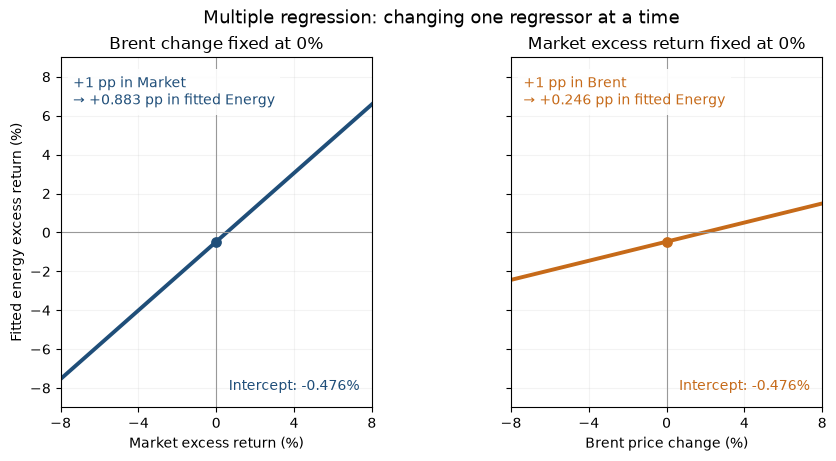

In [8]:
alpha = multiple.params["const"]
beta_market = multiple.params["Market"]
beta_brent = multiple.params["Brent"]
market_grid = np.linspace(-8, 8, 100)
brent_grid = market_grid.copy()
market_colour, brent_colour = "#1F4E79", "#C66A19"

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharex=True, sharey=True,
                         constrained_layout=True)
panels = [
    (axes[0], market_grid, alpha + beta_market * market_grid,
     market_colour, "Market excess return (%)", "Brent change fixed at 0%",
     beta_market, "Market"),
    (axes[1], brent_grid, alpha + beta_brent * brent_grid,
     brent_colour, "Brent price change (%)", "Market excess return fixed at 0%",
     beta_brent, "Brent"),
]
for ax, grid, fitted, colour, xlabel, title, beta, name in panels:
    ax.plot(grid, fitted, color=colour, lw=2.8)
    ax.scatter([0], [alpha], color=colour, s=45, zorder=3)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.axvline(0, color="0.6", lw=0.8)
    ax.grid(alpha=0.15)
    ax.set(xlabel=xlabel, title=title, xlim=(-8, 8), ylim=(-9, 9))
    ax.set_xticks([-8, -4, 0, 4, 8])
    ax.set_aspect("equal", adjustable="box")
    ax.text(0.04, 0.95, f"+1 pp in {name}\n→ {beta:+.3f} pp in fitted Energy",
            transform=ax.transAxes, va="top", fontsize=10, color=colour,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
    ax.text(0.96, 0.05, f"Intercept: {alpha:.3f}%",
            transform=ax.transAxes, ha="right", color=colour, fontsize=10)
axes[0].set_ylabel("Fitted energy excess return (%)")
fig.suptitle("Multiple regression: changing one regressor at a time", fontsize=13)
plt.show()

### The regression plane

The same slopes appear in 3D: **blue** varies Market with Brent fixed at zero;
**orange** varies Brent with Market fixed at zero. The surface shows fitted returns.
Observations are omitted to keep the plane visible.

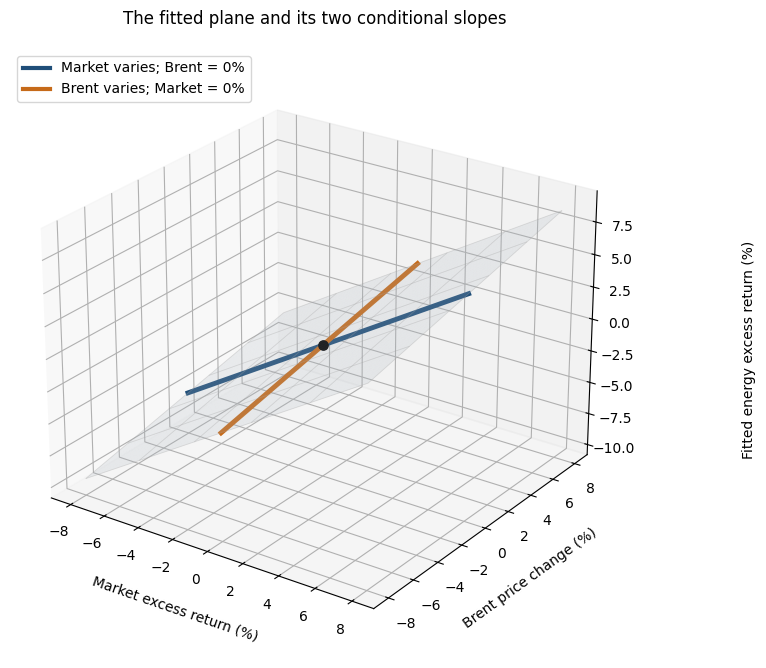

In [9]:
from matplotlib.lines import Line2D

market_mesh, brent_mesh = np.meshgrid(market_grid, brent_grid)
energy_mesh = alpha + beta_market * market_mesh + beta_brent * brent_mesh

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(market_mesh, brent_mesh, energy_mesh,
                color="#B9C4CE", alpha=0.20, linewidth=0)
ax.plot_wireframe(market_mesh, brent_mesh, energy_mesh,
                  rstride=20, cstride=20, color="0.65", alpha=0.35, linewidth=0.6)
ax.plot(market_grid, np.zeros_like(market_grid),
        alpha + beta_market * market_grid, color=market_colour, lw=3.5)
ax.plot(np.zeros_like(brent_grid), brent_grid,
        alpha + beta_brent * brent_grid, color=brent_colour, lw=3.5)
ax.scatter([0], [0], [alpha], color="black", s=45, depthshade=False)
ax.set_xlabel("Market excess return (%)", labelpad=10)
ax.set_ylabel("Brent price change (%)", labelpad=10)
# Use figure text so the vertical-axis label remains visible in inline output.
ax.set_zlabel("")
ax.set_title("The fitted plane and its two conditional slopes", pad=18)
ax.set_box_aspect((1.2, 1.2, 0.9))
ax.view_init(elev=25, azim=-55)
ax.legend(handles=[
    Line2D([], [], color=market_colour, lw=3, label="Market varies; Brent = 0%"),
    Line2D([], [], color=brent_colour, lw=3, label="Brent varies; Market = 0%"),
], loc="upper left", fontsize=10)
fig.subplots_adjust(left=0.02, right=0.87, bottom=0.05, top=0.92)
fig.text(0.88, 0.49, "Fitted energy excess return (%)",
         rotation=90, ha="center", va="center")
plt.show()

## Comparing the models

The table compares coefficients, HAC standard errors and fit on the same sample.
The residual standard deviation measures unexplained return variation, in
percentage points; it differs from a coefficient's standard error.

In [10]:
models = {"Market only": simple, "Market + Brent": multiple}
comparison = pd.DataFrame({
    name: {"Observations": int(model.nobs),
           "Alpha (% per month)": model.params["const"],
           "Market beta": model.params["Market"],
           "SE: market beta": model.bse["Market"],
           "R-squared": model.rsquared,
           "Adjusted R-squared": model.rsquared_adj,
           "Residual SD (pp)": np.sqrt(model.mse_resid)}
    for name, model in models.items()
})
display(comparison.round(4))
print(f"Market–Brent sample correlation: {returns['Market'].corr(returns['Brent']):.3f}")

,Market only,Market + Brent
Observations,180.0000,180.0000
Alpha (% per month),-0.6295,-0.4757
Market beta,1.1672,0.8825
SE: market beta,0.1946,0.1787
R-squared,0.4010,0.5306
Adjusted R-squared,0.3977,0.5253
Residual SD (pp),6.0268,5.3503


Market–Brent sample correlation: 0.394


### R-squared and adjusted R-squared

Let $y_t$ be energy excess return, $\widehat y_t$ its fitted value and
$\widehat u_t=y_t-\widehat y_t$ the residual. With an intercept,

$$SSE=\sum_{t=1}^{n}\widehat u_t^2,\qquad
SST=\sum_{t=1}^{n}(y_t-\bar y)^2,\qquad
R^2=1-\frac{SSE}{SST}.$$

$R^2$ is the fraction of sample return variation explained by the fitted model.
Adding Brent cannot increase SSE or lower $R^2$, because the multiple model includes
the market-only model as the case where the Brent coefficient is zero. This comparison
requires the same dependent variable and observations.

Adjusted $R^2$ accounts for the number of estimated slopes:

$$\bar R^2=1-\frac{SSE/(n-k-1)}{SST/(n-1)}
=1-\frac{n-1}{n-k-1}(1-R^2),$$

where $n$ is the number of observations and $k$ the number of regressors excluding
the intercept. Here $n=180$; $k=1$ for Market only and $k=2$ for Market + Brent.
Adjusted $R^2$ can increase, decrease or remain unchanged when a regressor is added:
the reduction in SSE must be large enough to offset the loss of a residual degree
of freedom. Better in-sample fit does not establish causality or guarantee better forecasts.

### Omitted variable bias

Write $M_t=r^e_{M,t}$ and $B_t=\Delta p^{Brent}_t$. Suppose the population model is

$$y_t=\alpha+\beta_M M_t+\beta_O B_t+u_t,\qquad E[u_t\mid M_t,B_t]=0.$$

The slope of the population regression that omits Brent is

$$\beta_M^{\mathrm{simple}}=\beta_M+\beta_O\delta,\qquad
\delta=\frac{\operatorname{Cov}(M_t,B_t)}{\operatorname{Var}(M_t)}.$$

The omitted-variable bias is therefore $\beta_O\delta$. It arises when Brent is
relevant for Energy ($\beta_O\ne0$) and correlated with Market ($\delta\ne0$).
Its sign depends on both terms: if both are positive, omitting Brent raises the
population market slope relative to $\beta_M$.

For the two OLS regressions with intercepts on the same sample, the corresponding
coefficient identity holds exactly:

$$\widehat\beta_M^{\mathrm{simple}}-\widehat\beta_M^{\mathrm{multiple}}
=\widehat\beta_O\widehat\delta,\qquad
\widehat\delta=
\frac{\sum_t(M_t-\bar M)(B_t-\bar B)}{\sum_t(M_t-\bar M)^2}.$$

Here the Brent coefficient and Market–Brent correlation are positive, and the
market slope falls when Brent is included. The sample identity explains this change;
interpreting it as bias relative to a correctly specified population model requires
the assumptions above. A changed coefficient alone does not establish a causal effect.
HAC standard errors do not remove omitted-variable bias.